                  Same Dataset
                       │
          ┌────────────┼────────────┐
          ↓            ↓            ↓
      No Prep       Minimal      Aggressive
          │            │            │
          └────────────┼────────────┘
                       ↓
                  Same Model
                       ↓
              Compare Results

In [1]:

import re
import unicodedata
import nltk
import pandas as pd

from bs4 import BeautifulSoup
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report


In [2]:
# downloading the required NLTK resources


nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")


[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\yuvan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\yuvan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\yuvan\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\yuvan\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [3]:

import random
import pandas as pd

rng = random.Random(42)

positive_reviews = [
    "the movie was wonderful",
    "the film was fantastic",
    "the acting was excellent",
    "the story was engaging",
    "the performances were brilliant",
    "the movie was enjoyable",
    "the direction was impressive",
    "the characters were believable",
    "the soundtrack was beautiful",
    "the film was entertaining",
    "I loved the movie",
    "I really enjoyed the film",
    "I would recommend this movie",
    "the ending was satisfying",
    "the screenplay was clever",
    "the visuals were stunning",
    "the actors delivered great performances",
    "the film exceeded my expectations",
    "the humor worked really well",
    "the movie kept me interested"
]

negative_reviews = [
    "the movie was terrible",
    "the film was awful",
    "the acting was horrible",
    "the story was boring",
    "the performances were disappointing",
    "the movie was unenjoyable",
    "the direction was poor",
    "the characters were unbelievable",
    "the soundtrack was annoying",
    "the film was tedious",
    "I hated the movie",
    "I really disliked the film",
    "I would not recommend this movie",
    "the ending was disappointing",
    "the screenplay was weak",
    "the visuals were unimpressive",
    "the actors delivered poor performances",
    "the film failed my expectations",
    "the humor did not work",
    "the movie lost my interest"
]

# Ten sentence styles × twenty review statements = 200 examples
styles = [
    "{}.",
    "Honestly, {}.",
    "In my opinion, {}.",
    "Overall, {}.",
    "After watching it, I think {}.",
    "My verdict: {}.",
    "For me, {}.",
    "To be fair, {}.",
    "I have to say that {}.",
    "My review is simple: {}."
]

# Some statements need grammar adjustments in certain styles.
# Using the review statements as written keeps the examples understandable.
def make_reviews(statements, label):
    reviews = []

    for statement in statements:
        for style in styles:
            text = style.format(statement)
            reviews.append((text, label))

    return reviews

data = (
    make_reviews(positive_reviews, 1)
    + make_reviews(negative_reviews, 0)
)

# Add formatting noise without changing the sentiment label.
noisy_data = []

for i, (text, label) in enumerate(data):
    version = i % 5

    if version == 1:
        text = text.upper()
    elif version == 2:
        text = f"<p>{text}</p>"
    elif version == 3:
        text = f"   {text}    "
    elif version == 4:
        text = f"{text} Visit https://example.com"

    noisy_data.append((text, label))

rng.shuffle(noisy_data)

df = pd.DataFrame(noisy_data, columns=["text", "label"])

texts = df["text"].tolist()
labels = df["label"].tolist()

print("Total reviews:", len(df))
print("\nClass distribution:")
print(df["label"].value_counts().sort_index().rename(
    index={0: "Negative", 1: "Positive"}
))

print("\nSample reviews:")
print(df.sample(5, random_state=42).to_string(index=False))


Total reviews: 400

Class distribution:
label
Negative    200
Positive    200
Name: count, dtype: int64

Sample reviews:
                                                                  text  label
                                                   the film was awful.      0
                                               the direction was poor.      0
My review is simple: the movie was terrible. Visit https://example.com      0
               <p>In my opinion, the characters were unbelievable.</p>      0
           <p>To be fair, the actors delivered great performances.</p>      1


In [4]:
# stratergy 1  - No Preprocessing


X_no_prep = texts.copy()

print(X_no_prep[0])

My review is simple: the performances were disappointing. Visit https://example.com


In [5]:
# stratergy 2 - Minimal Preprocessing


def minimal_preprocess(text):
    # 1. Normalize Unicode representation
    text = unicodedata.normalize("NFC", text)

    # 2. Remove HTML tags
    text = BeautifulSoup(text, "html.parser").get_text(" ")

    # 3. Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


In [6]:

X_minimal = [
    minimal_preprocess(text)
    for text in texts
]

for original, cleaned in zip(texts[:3], X_minimal[:3]):
    print("Original:", original)
    print("Minimal: ", cleaned)
    print("-" * 50)


Original: My review is simple: the performances were disappointing. Visit https://example.com
Minimal:  My review is simple: the performances were disappointing. Visit https://example.com
--------------------------------------------------
Original: After watching it, I think the film was entertaining. Visit https://example.com
Minimal:  After watching it, I think the film was entertaining. Visit https://example.com
--------------------------------------------------
Original:    I have to say that the visuals were stunning.    
Minimal:  I have to say that the visuals were stunning.
--------------------------------------------------


In [7]:

def aggressive_preprocess(text):
    # 1. Unicode normalization
    text = unicodedata.normalize("NFC", text)

    # 2. Remove HTML
    text = BeautifulSoup(text, "html.parser").get_text(" ")

    # 3. Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", "", text)

    # 4. Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # 5. Lowercase
    text = text.lower()

    # 6. Tokenize
    tokens = word_tokenize(text)

    # 7. Remove stopwords and punctuation-only tokens
    stop_words = set(stopwords.words("english"))
    tokens = [
        token for token in tokens
        if token not in stop_words
        and any(char.isalnum() for char in token)
    ]

    # 8. Lemmatize (basic noun-default version)
    lemmatizer = WordNetLemmatizer()
    tokens = [lemmatizer.lemmatize(token) for token in tokens]

    return " ".join(tokens)


In [8]:

X_aggressive = [
    aggressive_preprocess(text)
    for text in texts
]

for i in range(3):
    print("ORIGINAL:  ", X_no_prep[i])
    print("MINIMAL:   ", X_minimal[i])
    print("AGGRESSIVE:", X_aggressive[i])
    print("-" * 80)


ORIGINAL:   My review is simple: the performances were disappointing. Visit https://example.com
MINIMAL:    My review is simple: the performances were disappointing. Visit https://example.com
AGGRESSIVE: review simple performance disappointing visit
--------------------------------------------------------------------------------
ORIGINAL:   After watching it, I think the film was entertaining. Visit https://example.com
MINIMAL:    After watching it, I think the film was entertaining. Visit https://example.com
AGGRESSIVE: watching think film entertaining visit
--------------------------------------------------------------------------------
ORIGINAL:      I have to say that the visuals were stunning.    
MINIMAL:    I have to say that the visuals were stunning.
AGGRESSIVE: say visuals stunning
--------------------------------------------------------------------------------


In [9]:

from nltk.tokenize import word_tokenize

def get_tokens(texts):
    all_tokens = []

    for text in texts:
        all_tokens.extend(word_tokenize(text.lower()))

    return all_tokens


strategies = {
    "No preprocessing": X_no_prep,
    "Minimal": X_minimal,
    "Aggressive": X_aggressive
}

results = []

for name, processed_texts in strategies.items():
    tokens = get_tokens(processed_texts)
    vocabulary = set(tokens)

    results.append({
        "Strategy": name,
        "Total tokens": len(tokens),
        "Vocabulary size": len(vocabulary)
    })

comparison_df = pd.DataFrame(results)
print(comparison_df.to_string(index=False))


        Strategy  Total tokens  Vocabulary size
No preprocessing          4210              128
         Minimal          3810               91
      Aggressive          1420               68


In [10]:

X_no_train, X_no_test, y_train, y_test = train_test_split(
    X_no_prep,
    labels,
    test_size=0.33,
    random_state=42,
    stratify=labels
)

X_min_train, X_min_test, _, _ = train_test_split(
    X_minimal,
    labels,
    test_size=0.33,
    random_state=42,
    stratify=labels
)

X_agg_train, X_agg_test, _, _ = train_test_split(
    X_aggressive,
    labels,
    test_size=0.33,
    random_state=42,
    stratify=labels
)

print("Training examples:", len(y_train))
print("Testing examples:", len(y_test))


Training examples: 268
Testing examples: 132


In [11]:

def evaluate_classifier(X_train, X_test, y_train, y_test):
    model = Pipeline([
        ("tfidf", TfidfVectorizer()),
        ("classifier", LogisticRegression(max_iter=1000))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    return model, accuracy_score(y_test, predictions)


results = []

strategies = {
    "No preprocessing": (X_no_train, X_no_test),
    "Minimal": (X_min_train, X_min_test),
    "Aggressive": (X_agg_train, X_agg_test)
}

models = {}

for name, (X_train, X_test) in strategies.items():
    model, accuracy = evaluate_classifier(
        X_train, X_test, y_train, y_test
    )

    models[name] = model

    results.append({
        "Strategy": name,
        "Accuracy": round(accuracy, 3)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


        Strategy  Accuracy
No preprocessing     0.985
         Minimal     0.985
      Aggressive     0.977


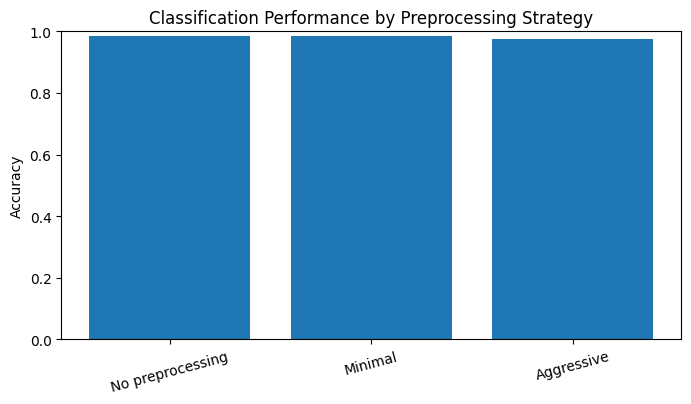

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.bar(results_df["Strategy"], results_df["Accuracy"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Classification Performance by Preprocessing Strategy")
plt.xticks(rotation=15)
plt.show()


# Module 4.2 — Compare Processing Strategies

## Objective
Compare three preprocessing strategies and evaluate their effects on token count, vocabulary size, information loss, and classification performance.

### 1. Preprocessing Strategies

- **No preprocessing:** Preserve the original text without cleaning.
- **Minimal preprocessing:** Apply Unicode normalization, HTML removal, and whitespace normalization while preserving most linguistic information.
- **Aggressive preprocessing:** Remove URLs, normalize case, tokenize, remove stopwords and punctuation-only tokens, and apply lemmatization.

### 2. Experimental Results

| Metric | No preprocessing | Minimal | Aggressive |
|---|---:|---:|---:|
| Total tokens | 4,210 | 3,810 | 1,420 |
| Vocabulary size | 128 | 91 | 68 |
| Accuracy | 98.5% | 98.5% | 97.7% |

**Classification setup:** TF-IDF + Logistic Regression, evaluated using a train/test split.

### 3. Key Observations

- Aggressive preprocessing reduced vocabulary size by approximately **46.9%** compared with no preprocessing.
- Accuracy decreased by only **0.8 percentage points** in this experiment.
- Reducing token count and vocabulary size can improve computational efficiency.
- Aggressive preprocessing can remove useful information, including negation, punctuation, emojis, and other meaningful details.
- More preprocessing does not automatically produce better classification performance.

### 4. Choosing a Strategy

- **Basic movie-review classification:** Aggressive preprocessing can be suitable if evaluation confirms acceptable performance.
- **Medical or clinical NLP:** Prefer minimal preprocessing initially and preserve important information such as negation, dosage, units, and symptoms.
- **General rule:** Select preprocessing based on the task, validation performance, information loss, and consequences of errors.

### Conclusion

The best preprocessing strategy balances computational efficiency with information preservation. Choose the least destructive strategy that achieves the required performance.

**Note:** These results came from a small, synthetic, template-generated dataset. They demonstrate the workflow but do not establish real-world performance.